# Generating Company Names with a Character-Level Transformer

**Author:** Mauro Reverberi

**Program:** MSc AI, Udacity Institute of AI & Technology / Woolf

**Project:** Capstone Project 5, Generative AI Applications

**Dataset:** Companies House, Free Company Data Product, snapshot of 2026-10-01:
https://download.companieshouse.gov.uk/en_output.html

TBD

**Research question:** Can a small character-level Transformer generate plausible and varied company names without mostly copying the names it was trained on or the names of companies that already exist?

I picked this task because it connects to my earlier capstone projects, which all work with company data for compliance checks. Project 1 built a dataset of Swiss legal entities from the GLEIF register, and Projects 2 to 4 analyzed company registrations, a bankruptcy score and negative news about companies. A later capstone project will build a due diligence agent that matches company names against registers and lists. Generated names could serve as extra test inputs for this step, names that look real but should not match anything. They are not a matching benchmark, which would need pairs of names that are known to be the same or different companies.

## Problem definition and dataset

**Task type:** TBD

**Dataset:** Companies House publishes a free monthly snapshot of all live companies on the UK register. I downloaded the snapshot of 2026-10-01 with 5,704,711 companies. Companies House imposes no rules on how the information on the public register is used, but rights of third parties in the data remain. The names are real register entries, nothing is synthetic, and I did not use this source in my earlier capstone projects.

`prepare_dataset.py` keeps the private limited companies whose names use only capital letters, digits and common punctuation, have at most 60 characters and end with LTD, LTD. or LIMITED. From the 5,259,281 different names it draws a random sample of 100,000 with seed 42. Very similar names like ACME HOLDINGS LTD and ACME HOLDINGS (UK) LIMITED form one group, so they cannot end up in training and test. The script splits the groups about 80/10/10 into train, validation and test. Names with the same first word and a different second word can still land in different splits.

The script also computes a key for every live company. The key follows the "same as" rules that Companies House uses to refuse a new name (Schedule 3 of the Names and Trading Disclosures Regulations 2015), so HANDS UK LTD and HAND'S LIMITED get the same key, and so do ACME 2 LTD and ACME TWO LTD. I wrote the key myself, and it is not the official test. It does not cover the exceptions or the separate "too like" test, which Companies House decides case by case. So a key match is only a possible collision with a real company, and a name without a match can still be too close to one. The 64-bit hashes of the keys are in `register_key_hashes.npy`, so a name can be checked against the register without keeping 5.7 million names in the repository.

## Setup

I use CUDA if it is available, otherwise the CPU. Seed 42 is the main seed of the notebook, the same as in `prepare_dataset.py`. I do not use the Apple GPU (MPS), because two runs with the same seed gave slightly different results there.

In [1]:
import math
import os
import random
import time
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

from constants import DATA_FILE, NAME_ENDINGS, REGISTER_FILE, SEED
from model import NameGPT
from ngram import CharNgram
from tokenizer import END, PAD, CharTokenizer

In [2]:
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 80)
# deterministic algorithms where possible, CUDA needs the cuBLAS setting, warn_only avoids errors
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
torch.use_deterministic_algorithms(True, warn_only=True)

In [3]:
# a name has at most 60 characters, plus the end marker in front
CONTEXT_SIZE = 61
BATCH_SIZE = 128
# larger batches for the evaluation, they need no gradients
EVAL_BATCH_SIZE = 512
EPOCHS = 20
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 0.01
# weights and loss history of the run that the text describes, written once
REFERENCE_DIR = Path("reference_run")
# a later training run goes here, a further run replaces its files
NEW_RUN_DIR = Path("new_run")
# True trains a model, False only loads a saved run
TRAIN_MODEL = True
# True analyses the reference run, False the run in NEW_RUN_DIR
ANALYSE_REFERENCE_RUN = True

In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"device: {device}")

device: cpu


In [5]:
def set_seed(seed):
    """Set the seed of random, NumPy and PyTorch, so a run can be repeated."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

set_seed(SEED)

## Load the dataset

I load the prepared sample, one row per company name, and the hashes of the register keys. I check the structure before I touch anything.

In [6]:
names = pd.read_csv(DATA_FILE, keep_default_na=False)
names["split"] = pd.Categorical(names["split"], ["train", "validation", "test"])
register_keys = np.load(REGISTER_FILE)
print(f"Rows: {names.shape[0]:,}, columns: {names.shape[1]}")
print(f"Register keys: {len(register_keys):,}")

Rows: 100,000, columns: 3
Register keys: 5,673,818


In [7]:
names.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 3 columns):
 #   Column  Non-Null Count   Dtype   
---  ------  --------------   -----   
 0   name    100000 non-null  str     
 1   group   100000 non-null  int64   
 2   split   100000 non-null  category
dtypes: category(1), int64(1), str(1)
memory usage: 1.6 MB


In [8]:
names.head()

,name,group,split
0,CF TROY UB INSURED LIMITED,17178,train
1,AHQENZA LIMITED,3582,train
2,INNSIGHT ADVISORS LTD,42646,train
3,HANN ELECTRICAL LTD,37927,train
4,GG-030-615 LIMITED,34636,train


The file has 100,000 rows and three columns, the name, the number of its name group and the split. No value is missing. All names are in capital letters, because the register stores almost all names this way and `prepare_dataset.py` removes the few others. Next to ordinary names like HANN ELECTRICAL LTD the first rows already show GG-030-615 LIMITED, which looks more like a code than a name.

The register file has 5,673,818 different keys for the 5,704,711 live companies of the snapshot, 30,893 fewer keys than company records. Some names may be allowed within a group of companies or with consent, and my key may also merge names that the official rules keep apart. I did not count the records per key.

## Data checks

Before I train anything I want to see what the names look like, how long they are, which characters and words appear and whether the split keeps related names together.

In [9]:
names.groupby("split", observed=True).sample(4, random_state=SEED)

,name,group,split
3974,MJ ROCKET LTD,57294,train
49261,IMPACT FLOORING SPECIALISTS LIMITED,42053,train
14637,EVD GUILDFORD LTD,29750,train
4623,SMITH HOUSING MORPETH LTD,79477,train
91140,RHODES&CO LIMITED,72462,validation
31094,POWERFUL POSITIONS LIMITED,67967,validation
98148,CITY ESSENTIALS LTD,18399,validation
36470,LINK MERCHANT SERVICES LTD,51009,validation
82742,PHONEGEEKS CITY LTD,66609,test
7625,SHULTON (GREAT BRITAIN) LIMITED,77952,test


In [10]:
names["length"] = names["name"].str.len()
names["ending"] = names["name"].str.split().str[-1]
names["words"] = names["name"].str.split().str.len()
print(names.groupby("split", observed=True)["name"].count())
print()
print("Endings:")
print(names["ending"].value_counts())
print()
print(names[["length", "words"]].describe().round(2))

split
train         80142
validation     9835
test          10023
Name: name, dtype: int64

Endings:
ending
LTD        51620
LIMITED    47376
LTD.        1004
Name: count, dtype: int64

          length      words
count  100000.00  100000.00
mean       22.97       3.49
std         7.81       1.03
min         6.00       2.00
25%        17.00       3.00
50%        22.00       3.00
75%        28.00       4.00
max        60.00      13.00


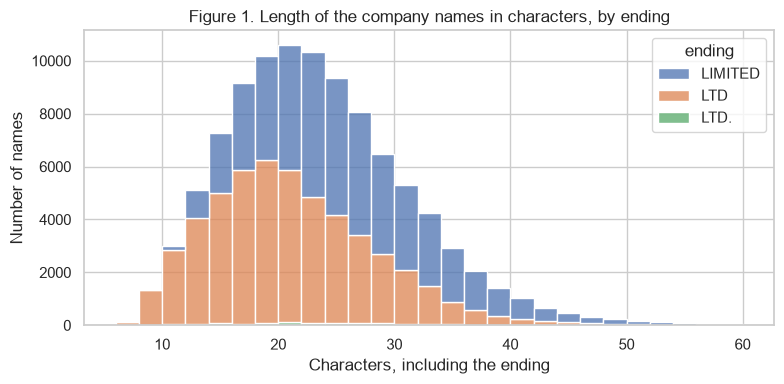

In [11]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=names, x="length", hue="ending", multiple="stack", binwidth=2, ax=ax)
ax.set_title("Figure 1. Length of the company names in characters, by ending")
ax.set_xlabel("Characters, including the ending")
ax.set_ylabel("Number of names")
plt.tight_layout()
plt.show()

**Interpretation:** 51,620 names end with LTD, 47,376 with LIMITED and only 1,004 with LTD. (with a full stop). The median name has 22 characters and 3 words. The maximum length is 60 characters, my limit, and the maximum word count is 13. Figure 1 shows that most names are between 10 and 40 characters long. The LTD names peak at about 20 characters and the LIMITED names a few characters later, which fits the four extra letters of LIMITED.

In [12]:
characters = Counter("".join(names["name"]))
print(f"{len(characters)} different characters")
print("".join(sorted(characters)))
print()
print("Rarest characters:")
print(sorted(characters.items(), key=lambda item: item[1])[:8])

48 different characters
 !&'()+,-./0123456789@ABCDEFGHIJKLMNOPQRSTUVWXYZ

Rarest characters:
[('!', 15), ('@', 33), ('+', 45), ('/', 93), (',', 373), ('9', 628), ('6', 676), ('7', 680)]


In [13]:
def name_words(name):
    """Return the words of a name without its ending LTD, LTD. or LIMITED."""
    words = name.split()
    return words[:-1] if words and words[-1] in NAME_ENDINGS else words


train_names = names.loc[names["split"] == "train", "name"].tolist()
word_counts = Counter(word for name in train_names for word in set(name_words(name)))
top_words = pd.DataFrame(word_counts.most_common(15), columns=["word", "names"])
top_words["share"] = (top_words["names"] / len(train_names)).round(4)
top_words

,word,names,share
0,SERVICES,3850,0.0480
1,&,3604,0.0450
2,PROPERTY,2113,0.0264
3,AND,1942,0.0242
4,GROUP,1873,0.0234
5,SOLUTIONS,1810,0.0226
6,MANAGEMENT,1806,0.0225
7,THE,1785,0.0223
8,PROPERTIES,1746,0.0218
9,HOLDINGS,1712,0.0214


**Interpretation:** After the preparation 48 different characters remain, the space, 26 capital letters, 10 digits and 11 punctuation marks. The rarest ones are `!` (15 times), `@` (33) and `+` (45). The most frequent words (without the ending) are generic business words. SERVICES appears in 4.8% of the training names, `&` in 4.5%, PROPERTY in 2.6%, followed by AND, GROUP, SOLUTIONS, MANAGEMENT, THE, PROPERTIES and HOLDINGS with about 2% each. No single word dominates.

In [14]:
# the preparation keeps every name group in one split, I check this first
splits_per_group = names.groupby("group")["split"].nunique()
spread = (splits_per_group > 1).sum()
print(f"Groups: {len(splits_per_group):,}, spread over more than one split: {spread}")
group_sizes = names["group"].value_counts()
shared = group_sizes[group_sizes > 1]
print(f"Groups with more than one name: {len(shared):,} ({shared.sum():,} names)")
largest = group_sizes.index[0]
names[names["group"] == largest].head(8)

Groups: 95,078, spread over more than one split: 0
Groups with more than one name: 1,901 (6,823 names)


,name,group,split,length,ending,words
3339,A&Z FARM (LINCOLN) LIMITED,1380,train,26,LIMITED,4
4001,A & L MOTS LTD,1380,train,14,LTD,5
4604,A & H JOINERY ASSOCIATES LTD,1380,train,28,LTD,6
4702,A&M LUXURY LIMITED,1380,train,18,LIMITED,3
5553,A & M MANAGEMENT LTD,1380,train,20,LTD,5
6280,A&S UK CONSULTING LIMITED,1380,train,25,LIMITED,4
6671,A&A BEAUTY CLINIC LTD,1380,train,21,LTD,4
9565,A&J DEVELOPMENTS (NW) LIMITED,1380,train,29,LIMITED,4


**Interpretation:** None of the 95,078 groups is spread over two splits. 1,901 groups have more than one name, 6,823 names in total, and all other names form a group of their own. The largest group shows a weakness of my rule. After the normalization, A&Z FARM (LINCOLN) LIMITED and A & L MOTS LTD both start with the words A AND, although they are clearly different companies. I did not count how many groups join different companies this way.

## Preprocessing for the model

The names are split into single characters. The `CharTokenizer` in `tokenizer.py` maps every character to an id and adds two special tokens. The padding token has the id 0, and the end marker `\n` (a line break, which never appears in a name) gets the id 1 and stands at the start and at the end of every name.

Every name becomes one row of `CONTEXT_SIZE` (61) ids. The input is the marker plus the name, the target the name plus the marker, and the rest of the row is padding.

In [15]:
tokenizer = CharTokenizer.train_from_names(train_names)
# the vocabulary comes from the training names only, so I check that no other split needs more
unseen = set("".join(names["name"])) - set("".join(train_names))
print(f"Characters in validation or test that are not in training: {len(unseen)}")
PAD_ID = tokenizer.token_id_for_char[PAD]
END_ID = tokenizer.token_id_for_char[END]
print(f"Vocabulary size: {tokenizer.vocabulary_size()}")
print(tokenizer.encode("ACME LTD"))
print(tokenizer.decode(tokenizer.encode("ACME LTD")))

Characters in validation or test that are not in training: 0
Vocabulary size: 50
[24, 26, 36, 28, 2, 35, 43, 27]
ACME LTD


In [16]:
def encode_names(name_list):
    """Return the input and target tensors, one row per name, padded with PAD_ID."""
    inputs = torch.full((len(name_list), CONTEXT_SIZE), PAD_ID, dtype=torch.long)
    targets = torch.full((len(name_list), CONTEXT_SIZE), PAD_ID, dtype=torch.long)
    for row, name in enumerate(name_list):
        ids = [END_ID] + tokenizer.encode(name) + [END_ID]
        inputs[row, :len(ids) - 1] = torch.tensor(ids[:-1])
        targets[row, :len(ids) - 1] = torch.tensor(ids[1:])
    return inputs, targets


data = {split: encode_names(names.loc[names["split"] == split, "name"].tolist())
        for split in ["train", "validation", "test"]}
for split, (inputs, targets) in data.items():
    to_predict = (targets != PAD_ID).sum().item()
    print(f"{split}: inputs {tuple(inputs.shape)}, characters to predict {to_predict:,}")
print()
print("First training name:", repr(train_names[0]))
print("input: ", data["train"][0][0, :12].tolist())
print("target:", data["train"][1][0, :12].tolist())

train: inputs (80142, 61), characters to predict 1,921,021
validation: inputs (9835, 61), characters to predict 235,552
test: inputs (10023, 61), characters to predict 240,086

First training name: 'CF TROY UB INSURED LIMITED'
input:  [1, 26, 29, 2, 43, 41, 38, 48, 2, 44, 25, 2]
target: [26, 29, 2, 43, 41, 38, 48, 2, 44, 25, 2, 32]


**Interpretation:** The vocabulary comes from the training names and has 50 tokens, the 48 characters plus padding and end marker. Validation and test contain no character that is missing in training. ACME LTD becomes eight ids and back again. The training split has 1,921,021 characters to predict (the end markers included), validation 235,552 and test 240,086. The first training name shows the shift by one place. The input starts with 1, the end marker, and the target with 26, the id of C.

## Reference model without deep learning

As a first model I build a simple reference, a character n-gram model from `ngram.py`. It counts which character follows the last n - 1 characters in the training names and turns the counts into probabilities. Add-k smoothing gives every character a small probability even after a context it never saw. I try the orders 2 to 5 and three values of k and keep the combination with the lowest validation loss, the cross-entropy per character in nats. The reference shows how far a model that only uses local contexts gets.

In [17]:
validation_names = names.loc[names["split"] == "validation", "name"].tolist()
test_names = names.loc[names["split"] == "test", "name"].tolist()

rows = []
for order in [2, 3, 4, 5]:
    for k in [0.01, 0.1, 1.0]:
        model_ngram = CharNgram(tokenizer, order, k).fit(train_names)
        rows.append({"order": order, "k": k, "validation_loss": model_ngram.loss(validation_names)})
ngram_results = pd.DataFrame(rows)
best_ngram = ngram_results.loc[ngram_results["validation_loss"].idxmin()]
ngram = CharNgram(tokenizer, int(best_ngram["order"]), best_ngram["k"]).fit(train_names)
print(f"Best reference: order {int(best_ngram['order'])}, k = {best_ngram['k']}, "
      f"validation loss {best_ngram['validation_loss']:.4f} nats per character")
ngram_results.pivot(index="order", columns="k", values="validation_loss").round(4)

Best reference: order 5, k = 0.1, validation loss 1.3680 nats per character


k,0.01,0.10,1.00
order,,,
2,2.3007,2.3004,2.3005
3,1.7570,1.7515,1.7573
4,1.4522,1.4283,1.4832
5,1.4046,1.3680,1.5350


**Interpretation:** The best loss falls with every step of the order, from 2.3004 nats per character for the bigram model to 1.3680 for the 5-gram model with k = 0.1. At order 5 a large k hurts (1.5350 with k = 1), probably because many contexts of four characters appear only a few times, and a large k then puts too much probability on characters that never followed them. I did not try orders above 5, where the contexts would be even rarer.

## Model

The architecture is the decoder-only Transformer from the course, built from my own PyTorch classes in `model.py` (`AttentionHead`, `MultiHeadAttention`, `FeedForward`, `Block` and `NameGPT`). Nothing is pretrained.

A token embedding and a learned position embedding turn every character into a vector of 256 numbers. Four blocks follow, each with causal self-attention over eight heads and a feed-forward part (256 to 1,024 to 256 with GELU), each part with a layer norm in front and a residual connection around it. A final layer norm and a linear layer give one logit per token. The causal mask lets a position see only itself and the earlier characters.

**Why this design:** company names are short, 61 positions are enough, but their structure reaches over more than a few characters, for example the ending or a closing bracket. Self-attention can use the whole name so far, the n-gram reference only the last four characters. I train from scratch instead of fine-tuning a pretrained model like GPT-2, because a pretrained model has read web text with real company names, so a copied name could also come from its pretraining.

In [18]:
config = {
    "vocabulary_size": tokenizer.vocabulary_size(),
    "context_size": CONTEXT_SIZE,
    "embedding_dim": 256,
    "heads_num": 8,
    "layers_num": 4,
    "dropout_rate": 0.1,
    "use_bias": False,
}
config["head_size"] = config["embedding_dim"] // config["heads_num"]

In [19]:
set_seed(SEED)
model = NameGPT(config).to(device)
total = sum(p.numel() for p in model.parameters())
print(f"Parameters: {total:,}")
# a quick check with an untrained model, the loss should be close to log(vocabulary size)
inputs, targets = data["validation"][0][:4].to(device), data["validation"][1][:4].to(device)
logits = model(inputs)
print(f"Logits shape: {tuple(logits.shape)}")
untrained_loss = F.cross_entropy(logits.reshape(-1, logits.shape[-1]), targets.reshape(-1),
                                 ignore_index=PAD_ID)
uniform_loss = math.log(config["vocabulary_size"])
print(f"Loss before training: {untrained_loss.item():.4f}, "
      f"log(vocabulary size) = {uniform_loss:.4f}")
print(model)

Parameters: 3,197,696
Logits shape: (4, 61, 50)
Loss before training: 4.0161, log(vocabulary size) = 3.9120
NameGPT(
  (token_embedding_layer): Embedding(50, 256)
  (positional_embedding_layer): Embedding(61, 256)
  (layers): Sequential(
    (0): Block(
      (multi_head): MultiHeadAttention(
        (heads): ModuleList(
          (0-7): 8 x AttentionHead(
            (Q_weights): Linear(in_features=256, out_features=32, bias=False)
            (K_weights): Linear(in_features=256, out_features=32, bias=False)
            (V_weights): Linear(in_features=256, out_features=32, bias=False)
            (dropout): Dropout(p=0.1, inplace=False)
          )
        )
        (linear): Linear(in_features=256, out_features=256, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
      )
      (layer_norm_1): LayerNorm((256,), eps=1e-05, elementwise_affine=True, bias=True)
      (feed_forward): FeedForward(
        (linear_layers): Sequential(
          (0): Linear(in_features=256, out_fe

**Interpretation:** The model has 3,197,696 parameters. Before training its loss on four validation names is 4.0161, close to log(50) = 3.9120, the loss of a model that gives all 50 tokens the same probability. So the forward pass and the loss work as expected with random weights. The printout shows the four identical blocks, each with eight heads of size 32.

## Training

The loss is the cross-entropy between the predicted distribution of the next character and the real next character, averaged over all characters and end markers, with the padding ignored. It measures how surprised the model is by the real names. The optimizer is AdamW with a learning rate of 1e-3, weight decay 0.01 and batches of 128 names. The learning rate and the weight decay are the default values of AdamW in PyTorch, and I did not search for better ones. Dropout 0.1 sits in the attention weights, after the attention output and after the feed-forward part.

I train for 20 epochs with a seeded batch order and keep the weights of the epoch with the lowest validation loss. The first run saves them in `reference_run`, a later run in `new_run`, and by default the analysis loads the reference run.

In [20]:
def run_epoch(model, inputs, targets, optimizer=None, generator=None):
    """Train one epoch with an optimizer or evaluate without one, return the loss per character."""
    training = optimizer is not None
    model.train(training)
    batch_size = BATCH_SIZE if training else EVAL_BATCH_SIZE
    loader = DataLoader(TensorDataset(inputs, targets), batch_size=batch_size, shuffle=training,
                        generator=generator)
    total, count = 0.0, 0
    with torch.set_grad_enabled(training):
        for batch_inputs, batch_targets in loader:
            # cut the padding columns that no name in this batch needs
            used = int((batch_targets != PAD_ID).sum(dim=1).max())
            batch_inputs = batch_inputs[:, :used].to(device)
            batch_targets = batch_targets[:, :used].to(device)
            logits = model(batch_inputs)
            loss = F.cross_entropy(logits.reshape(-1, logits.shape[-1]), batch_targets.reshape(-1),
                                   ignore_index=PAD_ID, reduction="sum")
            characters = (batch_targets != PAD_ID).sum().item()
            if training:
                optimizer.zero_grad(set_to_none=True)
                (loss / characters).backward()
                optimizer.step()
            total += loss.item()
            count += characters
    return total / count

In [21]:
set_seed(SEED)
model = NameGPT(config).to(device)
# the first run becomes the reference run, every later run goes to NEW_RUN_DIR
train_dir = NEW_RUN_DIR if (REFERENCE_DIR / "model_weights.pt").exists() else REFERENCE_DIR
if TRAIN_MODEL:
    print(f"training log of this run, saved in {train_dir}/")
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    generator = torch.Generator().manual_seed(SEED)
    history, best_loss, best_weights = [], math.inf, None
    for epoch in range(1, EPOCHS + 1):
        start = time.time()
        train_loss = run_epoch(model, *data["train"], optimizer=optimizer, generator=generator)
        validation_loss = run_epoch(model, *data["validation"])
        seconds = time.time() - start
        history.append({"epoch": epoch, "train_loss": train_loss,
                        "validation_loss": validation_loss, "seconds": seconds})
        print(f"epoch {epoch:2d}: train {train_loss:.4f}, validation {validation_loss:.4f} "
              f"({seconds:.0f} s)")
        if validation_loss < best_loss:
            best_loss = validation_loss
            best_weights = {name: t.detach().clone() for name, t in model.state_dict().items()}
    train_dir.mkdir(exist_ok=True)
    torch.save({name: t.cpu() for name, t in best_weights.items()}, train_dir / "model_weights.pt")
    pd.DataFrame(history).to_csv(train_dir / "training_history.csv", index=False)
    print(f"saved the weights and the loss history in {train_dir}/")

training log of this run, saved in reference_run/


epoch  1: train 1.5858, validation 1.3319 (248 s)


epoch  2: train 1.3168, validation 1.2549 (247 s)


epoch  3: train 1.2580, validation 1.2230 (246 s)


epoch  4: train 1.2248, validation 1.2045 (242 s)


...

epoch 16: train 1.0903, validation 1.1601 (247 s)


epoch 17: train 1.0839, validation 1.1600 (253 s)


epoch 18: train 1.0776, validation 1.1612 (246 s)


epoch 19: train 1.0716, validation 1.1651 (245 s)


epoch 20: train 1.0658, validation 1.1637 (248 s)
saved the weights and the loss history in reference_run/


In [22]:
# the text describes the reference run, ANALYSE_REFERENCE_RUN = False analyses the new run instead
run_dir = REFERENCE_DIR if ANALYSE_REFERENCE_RUN else NEW_RUN_DIR
model.load_state_dict(torch.load(run_dir / "model_weights.pt", map_location=device))
history = pd.read_csv(run_dir / "training_history.csv")
best_loss = history["validation_loss"].min()
best_epoch = int(history.loc[history["validation_loss"].idxmin(), "epoch"])
print(f"analysed run: {run_dir}/")
print(f"Best epoch: {best_epoch}, validation loss {best_loss:.4f}")

analysed run: reference_run/
Best epoch: 13, validation loss 1.1589


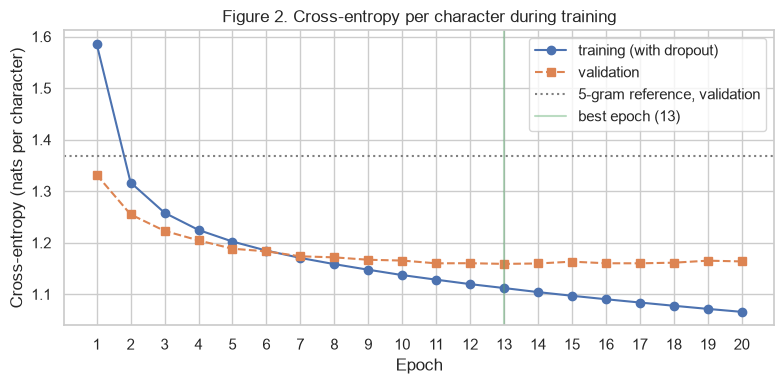

In [23]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(history["epoch"], history["train_loss"], marker="o", label="training (with dropout)")
ax.plot(history["epoch"], history["validation_loss"], marker="s", linestyle="--",
        label="validation")
ax.axhline(best_ngram["validation_loss"], color="grey", linestyle=":",
           label=f"{int(best_ngram['order'])}-gram reference, validation")
ax.axvline(best_epoch, color="C2", alpha=0.4, label=f"best epoch ({best_epoch})")
ax.set_title("Figure 2. Cross-entropy per character during training")
ax.set_xlabel("Epoch")
ax.set_ylabel("Cross-entropy (nats per character)")
ax.set_xticks(history["epoch"])
ax.legend()
plt.tight_layout()
plt.show()

**Interpretation:** In Figure 2 the training loss falls from 1.5858 to 1.0658 over the 20 epochs. The validation loss falls from 1.3319 to 1.1654 in epoch 10 and then only moves between 1.1589 and 1.1651, with its lowest value in epoch 13. These differences are small, so with other random numbers another epoch could have been selected. After the first epoch the model is already below the validation loss of the 5-gram reference (1.3680). The training loss is measured with dropout, so in the first six epochs it lies above the validation loss. Later it is lower, and the gap grows to 0.0979 in epoch 20. The model fits the training names better and better while new names hardly improve any more, which suggests mild overfitting.